In [407]:
import pandas as pd

# Load the credit card transaction dataset
df = pd.read_csv("../data/creditcard.csv")

# Display confirmation
print("Dataset loaded successfully!")

# Check the number of rows and columns
print("Dataset shape:", df.shape)

# Display the first 5 rows
display(df.head())

Dataset loaded successfully!
Dataset shape: (284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [408]:
# Count legitimate and fraudulent transactions
print("Transaction Class Distribution:")
print(df["Class"].value_counts())

# Calculate percentage of each class
print("\nPercentage Distribution:")
print(df["Class"].value_counts(normalize=True) * 100)

Transaction Class Distribution:
Class
0    284315
1       492
Name: count, dtype: int64

Percentage Distribution:
Class
0    99.827251
1     0.172749
Name: proportion, dtype: float64


In [409]:
# Check missing values
print("Missing values:")
print(df.isnull().sum().sum())

# Check duplicate rows
print("\nDuplicate rows:")
print(df.duplicated().sum())

# Check dataset information
print("\nDataset information:")
df.info()

Missing values:
0

Duplicate rows:
1081

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null 

In [410]:
# Identify duplicate rows
duplicate_rows = df[df.duplicated()]

# Check the class distribution of duplicate rows
print("Duplicate rows by class:")
print(duplicate_rows["Class"].value_counts())

# Check whether identical transaction features have conflicting labels
feature_cols = df.columns.drop("Class")

label_counts = df.groupby(list(feature_cols))["Class"].nunique()

print("\nTransactions with conflicting labels:")
print((label_counts > 1).sum())

Duplicate rows by class:
Class
0    1062
1      19
Name: count, dtype: int64

Transactions with conflicting labels:
0


In [411]:
# Store original dataset size
original_rows = len(df)

# Remove duplicate rows
df = df.drop_duplicates()

# Reset row index
df = df.reset_index(drop=True)

# Check the results
print("Original rows:", original_rows)
print("Rows after removing duplicates:", len(df))
print("Duplicates remaining:", df.duplicated().sum())

# Check updated class distribution
print("\nUpdated class distribution:")
print(df["Class"].value_counts())

Original rows: 284807
Rows after removing duplicates: 283726
Duplicates remaining: 0

Updated class distribution:
Class
0    283253
1       473
Name: count, dtype: int64


In [412]:
# Compare transaction amounts by class
amount_analysis = df.groupby("Class")["Amount"].agg(
    ["count", "mean", "median", "min", "max"]
)

print(amount_analysis)

        count        mean  median  min       max
Class                                           
0      283253   88.413575   22.00  0.0  25691.16
1         473  123.871860    9.82  0.0   2125.87


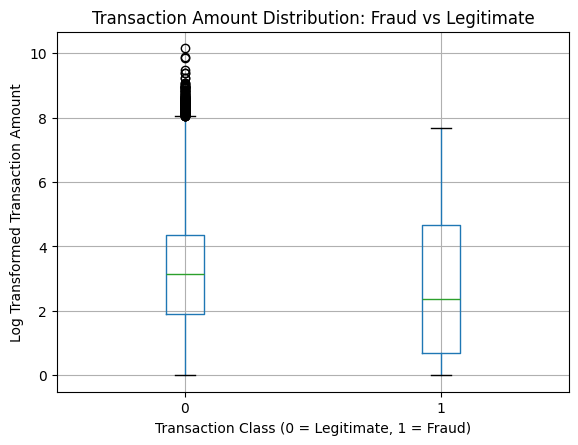

In [413]:
import matplotlib.pyplot as plt
import numpy as np

# Apply log transformation to handle large differences in amounts
df["Amount_log"] = np.log1p(df["Amount"])

# Create boxplot
df.boxplot(column="Amount_log", by="Class")

plt.title("Transaction Amount Distribution: Fraud vs Legitimate")
plt.suptitle("")
plt.xlabel("Transaction Class (0 = Legitimate, 1 = Fraud)")
plt.ylabel("Log Transformed Transaction Amount")
plt.show()

In [414]:
# Convert transaction time from seconds into hours
df["Time_hours"] = df["Time"] / 3600

# Group transactions into hourly intervals
df["Hour"] = df["Time_hours"].astype(int)

# Calculate total transactions and fraud rate per hour
hourly_analysis = df.groupby("Hour").agg(
    Total_Transactions=("Class", "count"),
    Fraud_Count=("Class", "sum"),
    Fraud_Rate=("Class", "mean")
)

# Convert fraud rate into percentage
hourly_analysis["Fraud_Rate"] *= 100

# Display first 10 hours
display(hourly_analysis.head(10))

,Total_Transactions,Fraud_Count,Fraud_Rate
Hour,,,
0,3931,2,0.050878
1,2213,2,0.090375
2,1573,21,1.335029
3,1818,13,0.715072
4,1082,6,0.554529
5,1679,11,0.655152
6,1822,3,0.164654
7,3366,23,0.683304
8,5148,5,0.097125


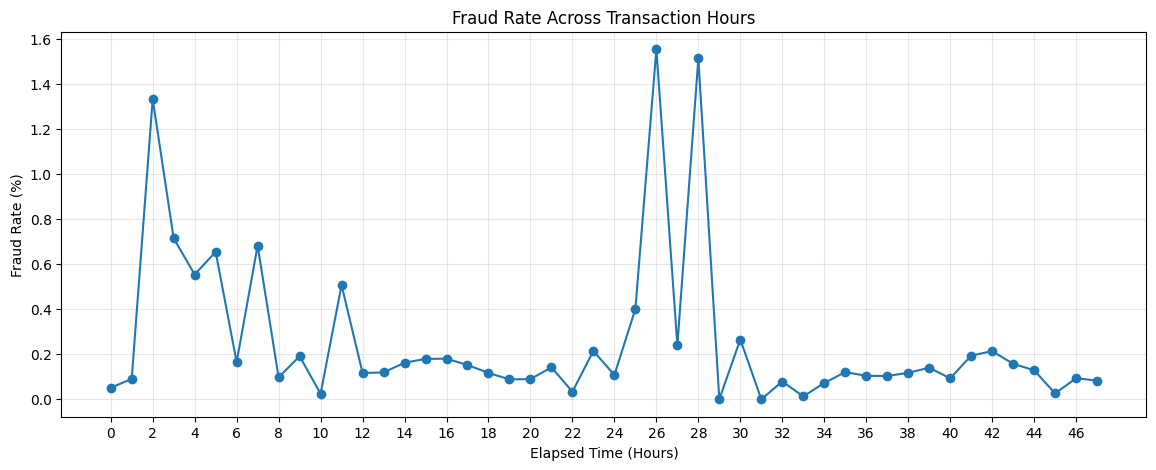

In [415]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))

plt.plot(
    hourly_analysis.index,
    hourly_analysis["Fraud_Rate"],
    marker="o"
)

plt.title("Fraud Rate Across Transaction Hours")
plt.xlabel("Elapsed Time (Hours)")
plt.ylabel("Fraud Rate (%)")
plt.xticks(range(0, 48, 2))
plt.grid(True, alpha=0.3)

plt.show()

In [416]:
# Select PCA-transformed features
features = [f"V{i}" for i in range(1, 29)]

# Calculate average feature values for each class
feature_comparison = df.groupby("Class")[features].mean()

# Calculate absolute difference between both classes
feature_difference = (
    feature_comparison.loc[0] - feature_comparison.loc[1]
).abs()

# Display the 10 features with the largest differences
top_features = feature_difference.sort_values(
    ascending=False
).head(10)

print("Top 10 features with the largest mean differences:")
display(top_features)

Top 10 features with the largest mean differences:


V14    6.847614
V3     6.742452
V17    6.474249
V12    6.112730
V10    5.460937
V7     5.186359
V1     4.511719
V4     4.483031
V16    4.008801
V11    3.722350
dtype: float64

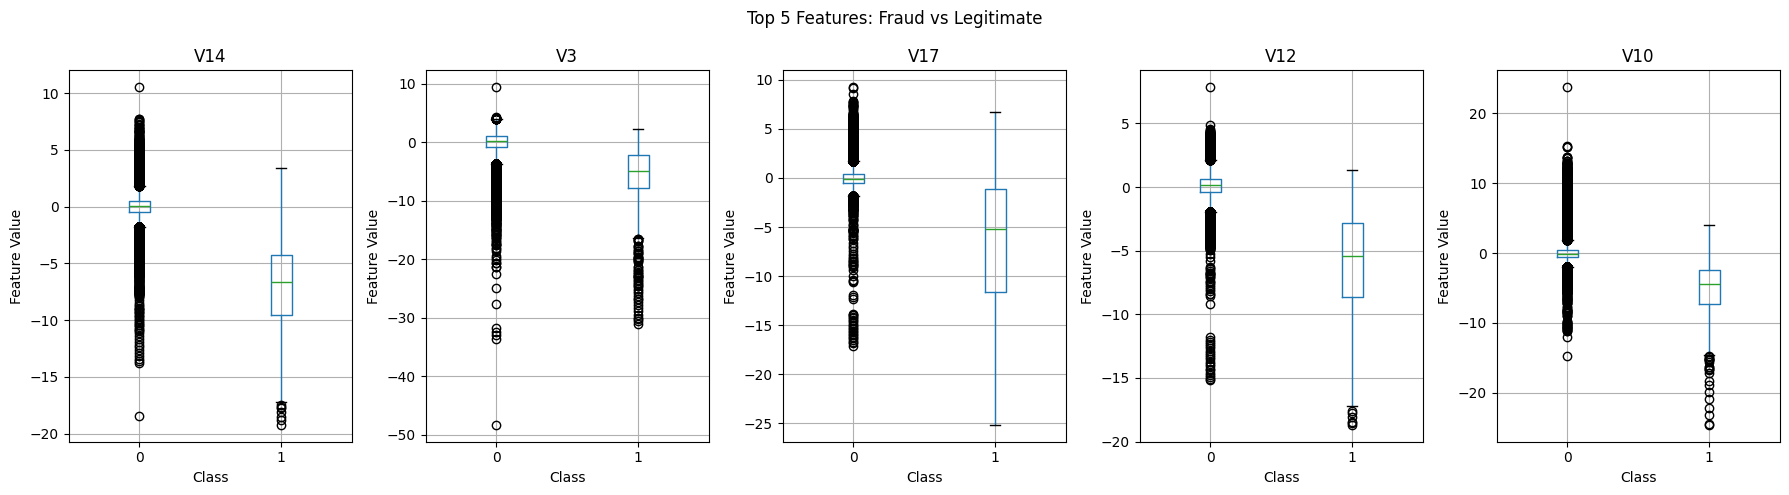

In [417]:
import matplotlib.pyplot as plt

top_5 = ["V14", "V3", "V17", "V12", "V10"]

fig, axes = plt.subplots(1, 5, figsize=(18, 5))

for i, feature in enumerate(top_5):
    df.boxplot(
        column=feature,
        by="Class",
        ax=axes[i]
    )

    axes[i].set_title(feature)
    axes[i].set_xlabel("Class")
    axes[i].set_ylabel("Feature Value")

plt.suptitle("Top 5 Features: Fraud vs Legitimate")
plt.tight_layout()
plt.show()

In [418]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Select original input features
X = df.drop(columns=[
    "Class", "Amount_log", "Time_hours", "Hour"
])

# Select target column
y = df["Class"]

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Scale the features
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Display dataset sizes
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

print("\nTraining class distribution:")
print(y_train.value_counts())

print("\nTesting class distribution:")
print(y_test.value_counts())

Training data: (226980, 30)
Testing data: (56746, 30)

Training class distribution:
Class
0    226602
1       378
Name: count, dtype: int64

Testing class distribution:
Class
0    56651
1       95
Name: count, dtype: int64


In [419]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    average_precision_score
)

# Create Logistic Regression model
lr_model = LogisticRegression(
    class_weight="balanced",
    max_iter=1000,
    random_state=42
)

# Train the model
lr_model.fit(X_train_scaled, y_train)

# Make predictions
y_pred = lr_model.predict(X_test_scaled)

# Calculate fraud probabilities
y_prob = lr_model.predict_proba(X_test_scaled)[:, 1]

# Evaluate the model
print("Classification Report:")
print(classification_report(y_test, y_pred))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print(
    "Average Precision (PR-AUC):",
    average_precision_score(y_test, y_prob)
)

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.98      0.99     56651
           1       0.06      0.87      0.11        95

    accuracy                           0.98     56746
   macro avg       0.53      0.92      0.55     56746
weighted avg       1.00      0.98      0.99     56746

Confusion Matrix:
[[55262  1389]
 [   12    83]]
Average Precision (PR-AUC): 0.6719244530518994


In [420]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    average_precision_score
)

# Create Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=200,
    class_weight="balanced_subsample",
    random_state=42,
    n_jobs=-1
)

# Train model
rf_model.fit(X_train_scaled, y_train)

# Make predictions
rf_pred = rf_model.predict(X_test_scaled)

# Calculate fraud probabilities
rf_prob = rf_model.predict_proba(X_test_scaled)[:, 1]

# Evaluate model
print("Random Forest Classification Report:")
print(classification_report(y_test, rf_pred))

print("Confusion Matrix:")
print(confusion_matrix(y_test, rf_pred))

print(
    "Average Precision:",
    average_precision_score(y_test, rf_prob)
)

Random Forest Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56651
           1       0.97      0.71      0.82        95

    accuracy                           1.00     56746
   macro avg       0.99      0.85      0.91     56746
weighted avg       1.00      1.00      1.00     56746

Confusion Matrix:
[[56649     2]
 [   28    67]]
Average Precision: 0.805866274777725


Top 10 Important Features:


,Feature,Importance
14,V14,0.179693
10,V10,0.121769
12,V12,0.108286
4,V4,0.107331
17,V17,0.092608
3,V3,0.058457
16,V16,0.058221
11,V11,0.049425
2,V2,0.029618
7,V7,0.022629


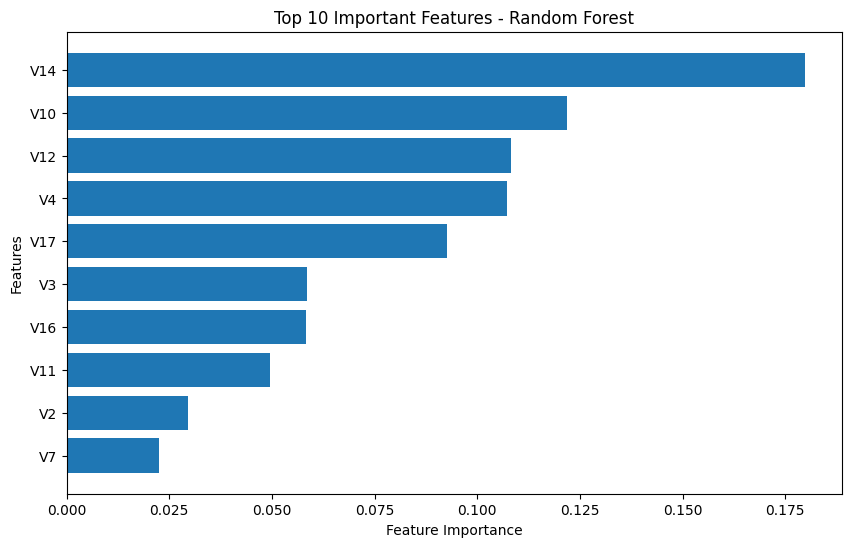

In [421]:
import pandas as pd
import matplotlib.pyplot as plt

# Extract feature importance
feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": rf_model.feature_importances_
})

# Sort features by importance
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

# Display top 10 features
print("Top 10 Important Features:")
display(feature_importance.head(10))

# Visualize feature importance
plt.figure(figsize=(10, 6))

plt.barh(
    feature_importance.head(10)["Feature"],
    feature_importance.head(10)["Importance"]
)

plt.gca().invert_yaxis()
plt.title("Top 10 Important Features - Random Forest")
plt.xlabel("Feature Importance")
plt.ylabel("Features")
plt.show()

In [422]:
from sklearn.ensemble import IsolationForest
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    average_precision_score
)

# Create Isolation Forest model
iso_model = IsolationForest(
    n_estimators=200,
    contamination=0.0017,
    random_state=42,
    n_jobs=-1
)

# Train using transaction features only
iso_model.fit(X_train_scaled)

# Predict anomalies
iso_raw_pred = iso_model.predict(X_test_scaled)

# Convert predictions:
# -1 = Anomaly (Fraud)
#  1 = Normal transaction

iso_pred = (iso_raw_pred == -1).astype(int)

# Obtain anomaly scores
iso_scores = -iso_model.score_samples(X_test_scaled)

# Evaluate model
print("Isolation Forest Classification Report:")
print(classification_report(y_test, iso_pred))

print("Confusion Matrix:")
print(confusion_matrix(y_test, iso_pred))

print(
    "Average Precision:",
    average_precision_score(y_test, iso_scores)
)

Isolation Forest Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56651
           1       0.20      0.20      0.20        95

    accuracy                           1.00     56746
   macro avg       0.60      0.60      0.60     56746
weighted avg       1.00      1.00      1.00     56746

Confusion Matrix:
[[56576    75]
 [   76    19]]
Average Precision: 0.10400318095977332


In [423]:
import pandas as pd
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    average_precision_score
)

results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest",
        "Isolation Forest"
    ],
    "Precision": [
        precision_score(y_test, y_pred),
        precision_score(y_test, rf_pred),
        precision_score(y_test, iso_pred)
    ],
    "Recall": [
        recall_score(y_test, y_pred),
        recall_score(y_test, rf_pred),
        recall_score(y_test, iso_pred)
    ],
    "F1 Score": [
        f1_score(y_test, y_pred),
        f1_score(y_test, rf_pred),
        f1_score(y_test, iso_pred)
    ],
    "Average Precision": [
        average_precision_score(y_test, y_prob),
        average_precision_score(y_test, rf_prob),
        average_precision_score(y_test, iso_scores)
    ]
})

display(results.round(4))

,Model,Precision,Recall,F1 Score,Average Precision
0,Logistic Regression,0.0564,0.8737,0.1059,0.6719
1,Random Forest,0.9710,0.7053,0.8171,0.8059
2,Isolation Forest,0.2021,0.2000,0.2011,0.1040


In [424]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Split existing training data into model-training and validation sets
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

# Scale using only the model-training data
tuning_scaler = StandardScaler()

X_fit_scaled = tuning_scaler.fit_transform(X_fit)
X_val_scaled = tuning_scaler.transform(X_val)

print("Model training size:", X_fit.shape)
print("Validation size:", X_val.shape)

print("\nValidation class distribution:")
print(y_val.value_counts())

Model training size: (181584, 30)
Validation size: (45396, 30)

Validation class distribution:
Class
0    45320
1       76
Name: count, dtype: int64


In [425]:
from sklearn.ensemble import RandomForestClassifier

rf_tune_model = RandomForestClassifier(
    n_estimators=200,
    class_weight="balanced_subsample",
    random_state=42,
    n_jobs=-1
)

rf_tune_model.fit(X_fit_scaled, y_fit)

# Get fraud probabilities on validation data
val_prob = rf_tune_model.predict_proba(X_val_scaled)[:, 1]

print("Validation predictions generated successfully!")

Validation predictions generated successfully!


In [426]:
from sklearn.metrics import precision_score, recall_score, f1_score

thresholds = [0.05, 0.10, 0.15, 0.20, 0.25, 0.30, 0.40, 0.50]

threshold_results = []

for threshold in thresholds:

    # Convert probabilities into predictions
    val_pred = (val_prob >= threshold).astype(int)

    # Calculate evaluation metrics
    precision = precision_score(y_val, val_pred, zero_division=0)
    recall = recall_score(y_val, val_pred, zero_division=0)
    f1 = f1_score(y_val, val_pred, zero_division=0)

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1
    })

threshold_df = pd.DataFrame(threshold_results)

display(threshold_df.round(4))

,Threshold,Precision,Recall,F1 Score
0,0.05,0.6768,0.8816,0.7657
1,0.10,0.8571,0.8684,0.8627
2,0.15,0.9041,0.8684,0.8859
3,0.20,0.9420,0.8553,0.8966
4,0.25,0.9420,0.8553,0.8966
5,0.30,0.9420,0.8553,0.8966
6,0.40,0.9552,0.8421,0.8951
7,0.50,0.9841,0.8158,0.8921


In [427]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    average_precision_score
)

# Transform test data using the tuning scaler
X_test_tuned_scaled = tuning_scaler.transform(X_test)

# Get fraud probabilities
test_prob = rf_tune_model.predict_proba(
    X_test_tuned_scaled
)[:, 1]

# Apply our selected threshold
selected_threshold = 0.20

test_pred_tuned = (
    test_prob >= selected_threshold
).astype(int)

# Evaluate tuned model
print("Tuned Random Forest - Threshold 0.20")

print("\nClassification Report:")
print(classification_report(y_test, test_pred_tuned))

print("Confusion Matrix:")
print(confusion_matrix(y_test, test_pred_tuned))

print(
    "\nAverage Precision:",
    average_precision_score(y_test, test_prob)
)

Tuned Random Forest - Threshold 0.20

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56651
           1       0.94      0.78      0.85        95

    accuracy                           1.00     56746
   macro avg       0.97      0.89      0.93     56746
weighted avg       1.00      1.00      1.00     56746

Confusion Matrix:
[[56646     5]
 [   21    74]]

Average Precision: 0.8104465348834909


In [428]:
# Sort transactions chronologically
df_time = df.sort_values("Time").reset_index(drop=True)

# Divide into earlier 80% and later 20%
split_point = int(len(df_time) * 0.80)

early_data = df_time.iloc[:split_point]
later_data = df_time.iloc[split_point:]

print("Earlier transactions:")
print(early_data["Class"].value_counts())

print("\nLater transactions:")
print(later_data["Class"].value_counts())

print("\nEarlier period:", early_data["Time"].min(),
      "to", early_data["Time"].max())

print("Later period:", later_data["Time"].min(),
      "to", later_data["Time"].max())

Earlier transactions:
Class
0    226581
1       399
Name: count, dtype: int64

Later transactions:
Class
0    56672
1       74
Name: count, dtype: int64

Earlier period: 0.0 to 145233.0
Later period: 145234.0 to 172792.0


In [429]:
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    average_precision_score
)

# Separate features and target
X_early = early_data.drop(
    columns=["Class", "Amount_log", "Time_hours", "Hour"]
)

y_early = early_data["Class"]

X_later = later_data.drop(
    columns=["Class", "Amount_log", "Time_hours", "Hour"]
)

y_later = later_data["Class"]

# Scale features using earlier data only
time_scaler = StandardScaler()

X_early_scaled = time_scaler.fit_transform(X_early)
X_later_scaled = time_scaler.transform(X_later)

# Train Random Forest
rf_time_model = RandomForestClassifier(
    n_estimators=200,
    class_weight="balanced_subsample",
    random_state=42,
    n_jobs=-1
)

rf_time_model.fit(X_early_scaled, y_early)

# Predict later transactions
time_pred = rf_time_model.predict(X_later_scaled)

time_prob = rf_time_model.predict_proba(
    X_later_scaled
)[:, 1]

# Evaluate
print("Chronological Random Forest Results:")
print(classification_report(y_later, time_pred))

print("Confusion Matrix:")
print(confusion_matrix(y_later, time_pred))

print(
    "Average Precision:",
    average_precision_score(y_later, time_prob)
)

Chronological Random Forest Results:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56672
           1       0.98      0.66      0.79        74

    accuracy                           1.00     56746
   macro avg       0.99      0.83      0.90     56746
weighted avg       1.00      1.00      1.00     56746

Confusion Matrix:
[[56671     1]
 [   25    49]]
Average Precision: 0.8159279648258089


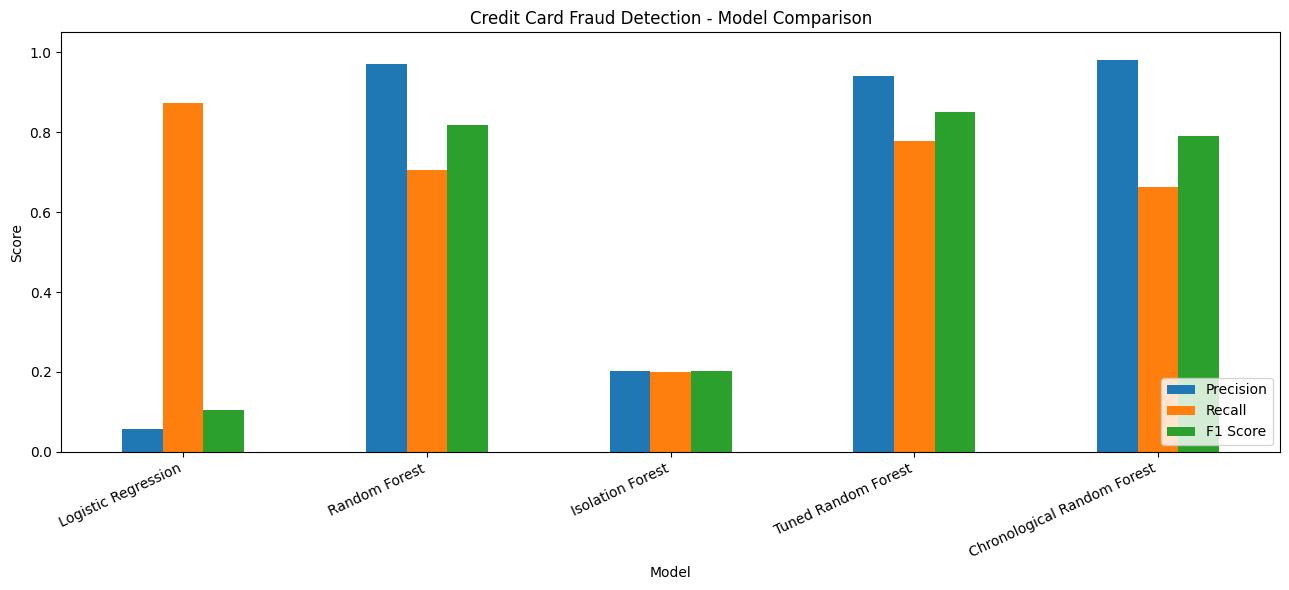

In [430]:
import pandas as pd
import matplotlib.pyplot as plt

final_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest",
        "Isolation Forest",
        "Tuned Random Forest",
        "Chronological Random Forest"
    ],
    "Precision": [
        0.0564, 0.9710, 0.2021, 0.94, 0.98
    ],
    "Recall": [
        0.8737, 0.7053, 0.2000, 0.7789, 0.6622
    ],
    "F1 Score": [
        0.1059, 0.8171, 0.2011, 0.8506, 0.7903
    ]
})

final_comparison.set_index("Model").plot(
    kind="bar",
    figsize=(13, 6)
)

plt.title("Credit Card Fraud Detection - Model Comparison")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=25, ha="right")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [431]:
# Split earlier transactions chronologically

time_split = int(len(early_data) * 0.80)

train_early = early_data.iloc[:time_split]
valid_early = early_data.iloc[time_split:]

print("Training transactions:", len(train_early))
print("Validation transactions:", len(valid_early))

print("\nTraining fraud cases:")
print(train_early["Class"].value_counts())

print("\nValidation fraud cases:")
print(valid_early["Class"].value_counts())

Training transactions: 181584
Validation transactions: 45396

Training fraud cases:
Class
0    181237
1       347
Name: count, dtype: int64

Validation fraud cases:
Class
0    45344
1       52
Name: count, dtype: int64


In [432]:
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier

# Separate features and target
X_time_train = train_early.drop(
    columns=["Class", "Amount_log", "Time_hours", "Hour"]
)
y_time_train = train_early["Class"]

X_time_val = valid_early.drop(
    columns=["Class", "Amount_log", "Time_hours", "Hour"]
)
y_time_val = valid_early["Class"]

# Scale features
chron_scaler = StandardScaler()

X_time_train_scaled = chron_scaler.fit_transform(X_time_train)
X_time_val_scaled = chron_scaler.transform(X_time_val)

# Train Random Forest
chron_model = RandomForestClassifier(
    n_estimators=200,
    class_weight="balanced_subsample",
    random_state=42,
    n_jobs=-1
)

chron_model.fit(X_time_train_scaled, y_time_train)

# Get validation fraud probabilities
chron_val_prob = chron_model.predict_proba(
    X_time_val_scaled
)[:, 1]

print("Chronological validation model trained successfully!")

Chronological validation model trained successfully!


In [433]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score
)

thresholds = [0.05, 0.10, 0.15, 0.20, 0.25, 0.30, 0.40, 0.50]

chron_results = []

for threshold in thresholds:

    val_predictions = (
        chron_val_prob >= threshold
    ).astype(int)

    chron_results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_time_val, val_predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_time_val, val_predictions, zero_division=0
        ),
        "F1 Score": f1_score(
            y_time_val, val_predictions, zero_division=0
        )
    })

chron_threshold_df = pd.DataFrame(chron_results)

display(chron_threshold_df.round(4))

,Threshold,Precision,Recall,F1 Score
0,0.05,0.7500,0.7500,0.7500
1,0.10,0.8298,0.7500,0.7879
2,0.15,0.9070,0.7500,0.8211
3,0.20,0.9512,0.7500,0.8387
4,0.25,0.9474,0.6923,0.8000
5,0.30,0.9474,0.6923,0.8000
6,0.40,0.9459,0.6731,0.7865
7,0.50,0.9429,0.6346,0.7586


In [434]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    average_precision_score
)

# Transform later transactions
X_later_scaled = chron_scaler.transform(X_later)

# Get fraud probabilities
final_prob = chron_model.predict_proba(
    X_later_scaled
)[:, 1]

# Apply selected threshold
final_threshold = 0.20

final_pred = (
    final_prob >= final_threshold
).astype(int)

# Final evaluation
print("FINAL CHRONOLOGICAL MODEL RESULTS")

print("\nClassification Report:")
print(classification_report(y_later, final_pred))

print("Confusion Matrix:")
print(confusion_matrix(y_later, final_pred))

print(
    "\nAverage Precision:",
    average_precision_score(y_later, final_prob)
)

FINAL CHRONOLOGICAL MODEL RESULTS

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56672
           1       0.92      0.76      0.83        74

    accuracy                           1.00     56746
   macro avg       0.96      0.88      0.91     56746
weighted avg       1.00      1.00      1.00     56746

Confusion Matrix:
[[56667     5]
 [   18    56]]

Average Precision: 0.7977758125977188


In [435]:
import joblib
from pathlib import Path

# Create model folder if it doesn't exist
Path("../models").mkdir(exist_ok=True)

# Package the trained model and preprocessing details
fraud_pipeline = {
    "model": chron_model,
    "scaler": chron_scaler,
    "threshold": 0.20,
    "features": list(X_time_train.columns)
}

# Save everything
joblib.dump(
    fraud_pipeline,
    "../models/fraud_detection_model.joblib"
)

print("Final model saved successfully!")

Final model saved successfully!
